In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import numpy as np, sympy as sp
from IPython.display import Image, display, Markdown
sp.init_printing(use_unicode=True)
def show(path):
    p = path[0] if isinstance(path, tuple) else path
    display(Image(filename=p))


# 11. Tensor power spectrum

Definition: $\langle\gamma_{ij}\gamma_{ij}\rangle=\int d\ln k\,\Delta_t^2$ with $\Delta_t^2=\frac{n_{pol}N_e k^3}{2\pi^2}|\gamma_k|^2$, $n_{pol}=2$, $N_e=2$.
For the exact Bunch-Davies mode this gives $\Delta_t^2=\frac{2H^2}{\pi^2M_{pl}^2}(1+k^2\eta^2)$, which is checked against numerically evolved modes.

In [2]:
from desitter_perturbations.spectra import polarization as pol, tensor_power as tp, parameter_sweeps as ps
k = np.array([0.3, -1.1, 0.8])
print("normalisation error  :", pol.check_normalization(k))
print("completeness error   :", pol.check_completeness(k))
print("transverse/traceless :", pol.check_transverse_traceless(k))
r = ps.sweep_wavenumber(n=12, k_min=0.2, k_max=100, eta_end=-1e-2, x_start=300)
print("max relative error of numerical spectrum:", r["rel_err"].max())

normalisation error  : 2.220446049250313e-16
completeness error   : 1.6653345369377348e-16
transverse/traceless : (6.456704520931514e-17, 2.7755575615628914e-17)


max relative error of numerical spectrum: 9.921160076649485e-12


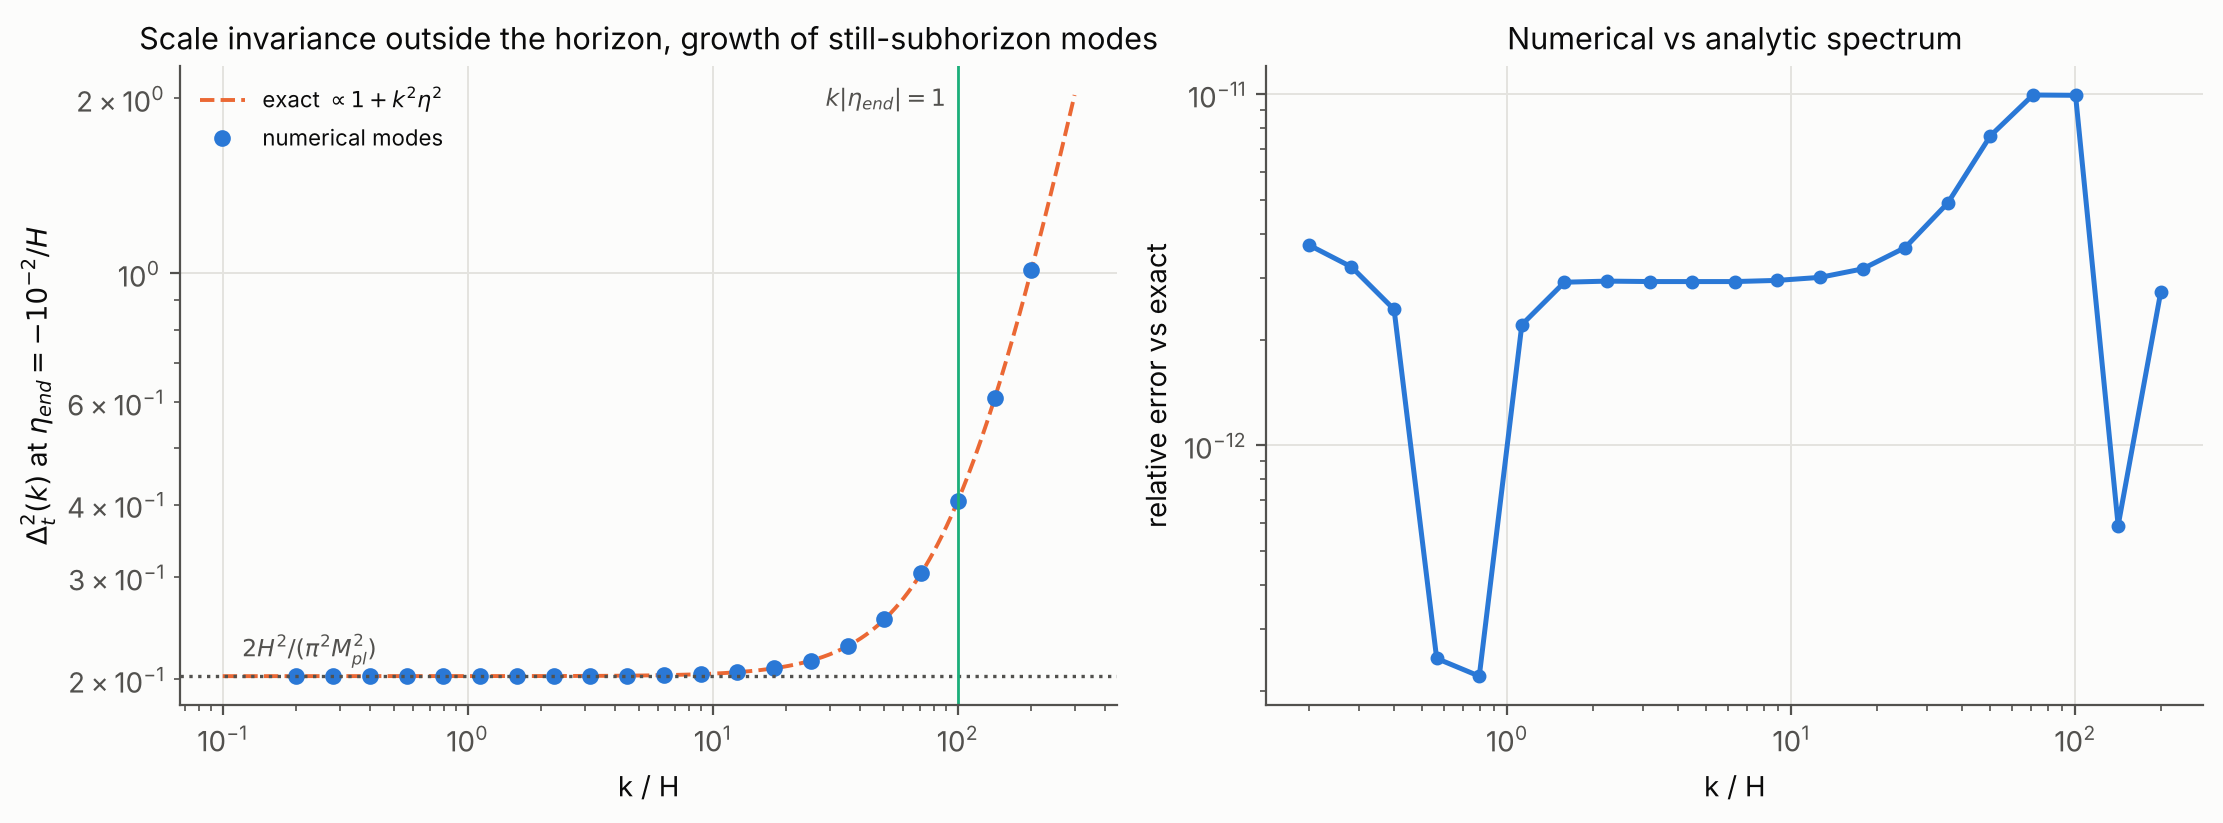

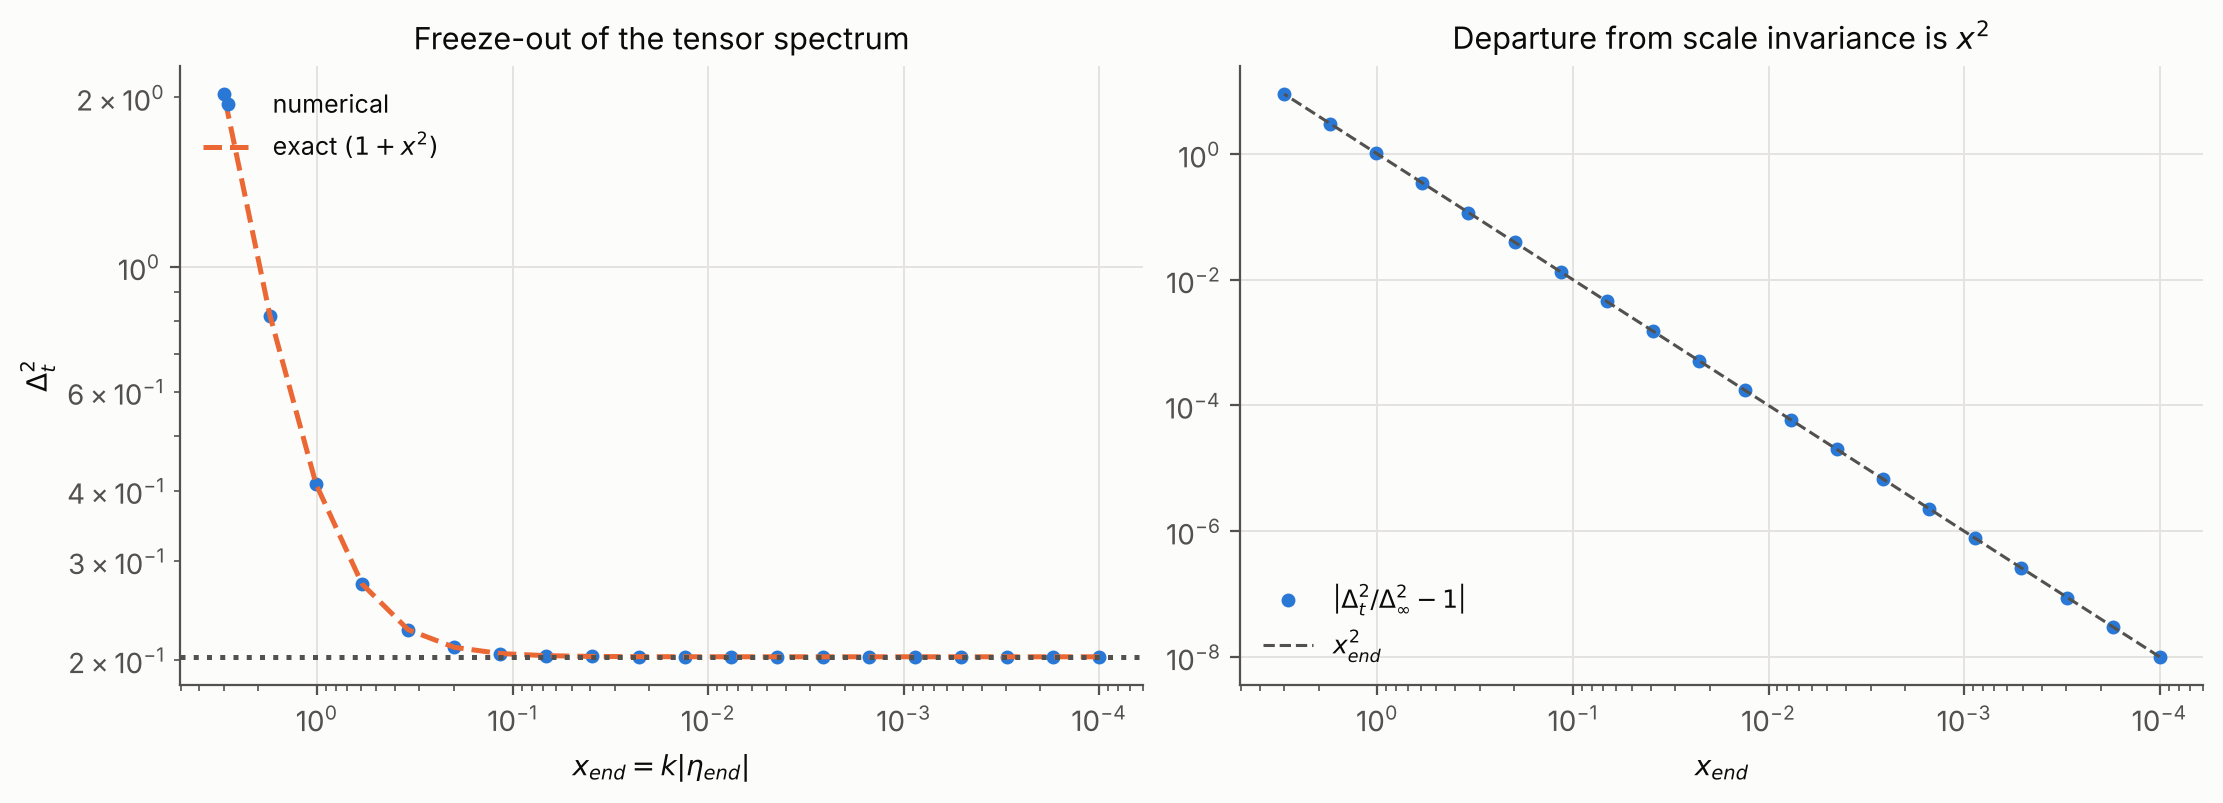

In [3]:
from desitter_perturbations.visualization import spectrum_plots as sp_
show(sp_.plot_tensor_spectrum()); show(sp_.plot_late_time())

The amplitude $2H^2/(\pi^2M_{pl}^2)$ is a benchmark for this implementation under the stated conventions; it is not a statement about the observed universe.